# **Cell 1**: Installing Dependencies

In [7]:
!pip install -q "sqlalchemy<2.0.0" pydicom pylidc tcia_utils onnx onnxruntime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython-sql 0.5.0 requires sqlalchemy>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.


# **Cell 2**: Configure Environment and Patch Scripts

In [8]:
import os

# 1. Setup pylidc config
with open('/root/.pylidcrc', 'w') as f:
    f.write("[dicom]\npath = /content/raw_data\nwarn = True\n")

# 2. Patch data_prep.py for Python 3.13 / NumPy 2.0 compatibility
with open('/content/data_prep.py', 'r') as f:
    prep_code = f.read()

patch = """import configparser
if not hasattr(configparser, 'SafeConfigParser'):
    configparser.SafeConfigParser = configparser.ConfigParser
import numpy as np
if not hasattr(np, 'int'):
    np.int = int
    np.float = float
    np.bool = bool
"""
if "np.int = int" not in prep_code:
    with open('/content/data_prep.py', 'w') as f:
        f.write(patch + '\n' + prep_code)

# 3. Patch train.py to load images as 3-channel RGB instead of 1-channel Grayscale
with open('/content/train.py', 'r') as f:
    train_code = f.read()

train_code = train_code.replace('.convert("L")', '.convert("RGB")')

with open('/content/train.py', 'w') as f:
    f.write(train_code)

print("Configuration and patches applied successfully!")

Configuration and patches applied successfully!


# **Cell 3**: Download and Reorganize Data

In [13]:
import os

with open('/root/.pylidcrc', 'w') as f:
    f.write("[dicom]\npath = /content/raw_data\nwarn = True\n")

# Patch with proper NumPy types
with open('/content/data_prep.py', 'r') as f:
    prep_code = f.read()
patch = """import configparser
if not hasattr(configparser, 'SafeConfigParser'):
    configparser.SafeConfigParser = configparser.ConfigParser
import numpy as np
if not hasattr(np, 'int'):
    np.int = np.int64
    np.float = np.float64
    np.bool = np.bool_
"""
if "np.int64" not in prep_code:
    with open('/content/data_prep.py', 'w') as f:
        f.write(patch + '\n' + prep_code)

with open('/content/train.py', 'r') as f:
    train_code = f.read()
train_code = train_code.replace('.convert("L")', '.convert("RGB")')
with open('/content/train.py', 'w') as f:
    f.write(train_code)

print("Scripts perfectly patched!")

Scripts perfectly patched!


In [14]:
import os
import glob
import shutil
import pydicom
import pylidc as pl
import pandas as pd
from tcia_utils import nbia

download_path = "/content/raw_data"
os.makedirs(download_path, exist_ok=True)

print("Fetching top 50 patients from database...")
scans = pl.query(pl.Scan).all()
top_patients = []
for scan in sorted(scans, key=lambda s: len(s.annotations), reverse=True):
    if scan.patient_id not in top_patients:
        top_patients.append(scan.patient_id)
    if len(top_patients) >= 50: break

df = pd.DataFrame(nbia.getSeries(collection="LIDC-IDRI"))
p_col = 'PatientID' if 'PatientID' in df.columns else 'Subject ID'
m_col = 'Modality' if 'Modality' in df.columns else 'modality'
s_col = 'SeriesInstanceUID' if 'SeriesInstanceUID' in df.columns else 'Series Instance UID'

subset = df[(df[m_col] == 'CT') & (df[p_col].isin(top_patients))].drop_duplicates(subset=p_col)
nbia.downloadSeries(subset[s_col].tolist(), input_type="list", path=download_path)

print("\nReorganizing folders so pylidc can read them...")
for series_dir in glob.glob(download_path + "/*"):
    if os.path.isdir(series_dir) and "LIDC" not in os.path.basename(series_dir):
        dcms = glob.glob(series_dir + "/*.dcm")
        if dcms:
            pid = pydicom.dcmread(dcms[0], stop_before_pixels=True).PatientID
            target_dir = os.path.join(download_path, pid)
            os.makedirs(target_dir, exist_ok=True)
            for dcm in dcms:
                try:
                    shutil.move(dcm, target_dir)
                except shutil.Error:
                    pass
        shutil.rmtree(series_dir)

print("Data downloaded and reorganized!")

Fetching top 50 patients from database...

Reorganizing folders so pylidc can read them...
Data downloaded and reorganized!


# **Cell 4**: Run Data Prep

In [15]:
!python /content/data_prep.py --output_dir /content/processed_data

# Delete the raw DICOMs to free up ~10GB of disk space before training
!rm -rf /content/raw_data
!echo "Raw DICOMs deleted. Processed data ready."

/usr/local/lib/python3.13/dist-packages/pylidc/__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr
Found 1018 scans. Processing...
  0% 0/1018 [00:00<?, ?it/s]Loading dicom files ... This may take a moment.
  [warn] could not load volume for LIDC-IDRI-0078: Couldn't find DICOM files for Scan(id=1,patient_id=LIDC-IDRI-0078) in /content/raw_data/LIDC-IDRI-0078
Loading dicom files ... This may take a moment.
  [warn] could not load volume for LIDC-IDRI-0069: Couldn't find DICOM files for Scan(id=2,patient_id=LIDC-IDRI-0069) in /content/raw_data/LIDC-IDRI-0069
Loading dicom files ... This may take a moment.
  [warn] could not load volume for LIDC-IDRI-0079: Couldn't find DICOM files for Scan(id=3,patient_id=LIDC-IDRI-0079) in /content/raw_data/LIDC-IDRI-0079

# **Cell 5**: Train the Model

In [16]:
!python /content/train.py \
  --manifest /content/processed_data/manifest.csv \
  --output_dir /content/checkpoints/ \
  --batch_size 16 \
  --num_workers 2 \
  --epochs 3

Using device: cuda
Train: 5686 slices from 40 patients
Val:   1556 slices from 10 patients
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
100% 9.83M/9.83M [00:00<00:00, 146MB/s]
Class balance in train set — positive: 1432, negative: 4254, pos_weight: 2.97
Epoch 01/3 | train loss 0.8376 auc 0.7504 acc 0.6154 | val loss 0.9264 auc 0.7446 acc 0.6806
  -> new best model saved (val AUC 0.7446)
Epoch 02/3 | train loss 0.7125 auc 0.8351 acc 0.7030 | val loss 0.8502 auc 0.7816 acc 0.6928
  -> new best model saved (val AUC 0.7816)
Epoch 03/3 | train loss 0.5749 auc 0.9026 acc 0.7879 | val loss 0.8383 auc 0.7887 acc 0.7082
  -> new best model saved (val AUC 0.7887)

Best val AUC: 0.7887
Best checkpoint: /content/checkpoints/best_model.pth
Next step: python export_onnx.py --checkpoint /content/checkpoints/best_model.pth --out tier0.onnx


# **Cell 6**: Export and Download

In [18]:
import os
from google.colab import files

# 1. Patch export_onnx.py to bypass the PyTorch 2.6 security block
export_file = '/content/export_onnx.py'
with open(export_file, 'r') as f:
    export_code = f.read()

# Add weights_only=False to the torch.load command
export_code = export_code.replace(
    'torch.load(args.checkpoint, map_location="cpu")',
    'torch.load(args.checkpoint, map_location="cpu", weights_only=False)'
)

with open(export_file, 'w') as f:
    f.write(export_code)

print("Patch applied. Exporting to ONNX...")

# 2. Export the PyTorch model to ONNX
!python /content/export_onnx.py \
  --checkpoint /content/checkpoints/best_model.pth \
  --out /content/tier0.onnx

# 3. Download the ONNX model (Put this on your UNO Q board)
if os.path.exists('/content/tier0.onnx'):
    print("Export successful! Triggering download for tier0.onnx...")
    files.download('/content/tier0.onnx')
else:
    print("Error: ONNX file not found.")

# 4. Download the PyTorch checkpoint (Keep this safe on your laptop!)
if os.path.exists('/content/checkpoints/best_model.pth'):
    print("Triggering download for best_model.pth...")
    files.download('/content/checkpoints/best_model.pth')

Patch applied. Exporting to ONNX...
Loaded /content/checkpoints/best_model.pth (epoch 3, val AUC 0.7886607020077009)
/content/export_onnx.py:54: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, args.out, dynamo=False, **kwargs)  # legacy exporter: stable for plain convnets
Wrote /content/tier0.onnx
cam shape (1, 1, 16, 16); worst PyTorch-vs-ONNX difference: 6.82e-05
Parity check passed. Copy the .onnx file to the UNO Q and set TIER0_MODEL=<path>.
Export successful! Triggering download for tier0.onnx...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggering download for best_model.pth...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Master Cell**


In [20]:
import os
from google.colab import files

# --- 1. INJECT THE "--resume" FEATURE INTO TRAIN.PY ---
with open('/content/train.py', 'r') as f:
    train_code = f.read()

if "--resume" not in train_code:
    # Add the argument
    train_code = train_code.replace(
        'parser.add_argument("--epochs"',
        'parser.add_argument("--resume", type=str, default=None)\n    parser.add_argument("--epochs"'
    )
    # Add the loading logic (bypassing the PyTorch 2.6 security block)
    train_code = train_code.replace(
        'model = build_model().to(device)',
        'model = build_model().to(device)\n    if args.resume:\n        ck = torch.load(args.resume, map_location=device, weights_only=False)\n        model.load_state_dict(ck["model_state_dict"])\n        print(f"\\n---> SUCCESSFULLY RESUMED FROM {args.resume} <---")'
    )
    with open('/content/train.py', 'w') as f:
        f.write(train_code)
    print("train.py successfully patched for resuming!")

# --- 2. RUN THE REMAINING 17 EPOCHS ---
# We point --resume directly at the checkpoint you just made!
print("Starting the remaining 17 epochs...\n")
!python /content/train.py \
  --manifest /content/processed_data/manifest.csv \
  --output_dir /content/checkpoints/ \
  --batch_size 16 \
  --num_workers 2 \
  --epochs 17 \
  --resume /content/checkpoints/best_model.pth

# --- 3. EXPORT THE FINAL MODEL ---
print("\nTraining complete! Exporting to final ONNX...")
!python /content/export_onnx.py \
  --checkpoint /content/checkpoints/best_model.pth \
  --out /content/tier0_final.onnx

# --- 4. DOWNLOAD THE FULLY BAKED FILES ---
if os.path.exists('/content/tier0_final.onnx'):
    print("Triggering download for final ONNX model...")
    files.download('/content/tier0_final.onnx')

if os.path.exists('/content/checkpoints/best_model.pth'):
    print("Triggering download for final PyTorch checkpoint...")
    files.download('/content/checkpoints/best_model.pth')

Starting the remaining 17 epochs...

Using device: cuda
Train: 5686 slices from 40 patients
Val:   1556 slices from 10 patients

---> SUCCESSFULLY RESUMED FROM /content/checkpoints/best_model.pth <---
Class balance in train set — positive: 1432, negative: 4254, pos_weight: 2.97
Epoch 01/17 | train loss 0.5664 auc 0.9048 acc 0.8002 | val loss 1.0953 auc 0.7667 acc 0.7172
  -> new best model saved (val AUC 0.7667)
Epoch 02/17 | train loss 0.5011 auc 0.9273 acc 0.8250 | val loss 0.9303 auc 0.7809 acc 0.7147
  -> new best model saved (val AUC 0.7809)
Epoch 03/17 | train loss 0.4423 auc 0.9438 acc 0.8512 | val loss 0.9927 auc 0.7929 acc 0.7102
  -> new best model saved (val AUC 0.7929)
Epoch 04/17 | train loss 0.4145 auc 0.9507 acc 0.8628 | val loss 1.0895 auc 0.7923 acc 0.7249
Epoch 05/17 | train loss 0.3759 auc 0.9605 acc 0.8846 | val loss 1.0874 auc 0.7874 acc 0.7307
Epoch 06/17 | train loss 0.3171 auc 0.9706 acc 0.9005 | val loss 1.2327 auc 0.7794 acc 0.6889
Epoch 07/17 | train loss 0.2

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggering download for final PyTorch checkpoint...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loading model and gathering 400 test images...
Running AI inference on 400 images... (This takes about 15 seconds)

   MINI VALIDATION RESULTS
Overall Accuracy : 87.2%
Precision        : 80.4%  (When it flags a nodule, how often is it right?)
Recall (Sens.)   : 98.5%  (Out of all real nodules, how many did it catch?)


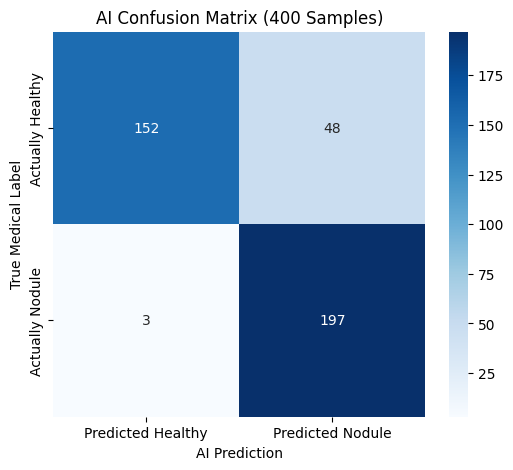

In [24]:
import onnxruntime as ort
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

print("Loading model and gathering 400 test images...")

# 1. Gather a balanced test set (200 positive, 200 negative)
manifest = pd.read_csv('/content/processed_data/manifest.csv')
pos_df = manifest[manifest['label'] == 1]
neg_df = manifest[manifest['label'] == 0]

sample_size = min(200, len(pos_df), len(neg_df))
test_df = pd.concat([pos_df.sample(sample_size), neg_df.sample(sample_size)]).sample(frac=1)

# 2. Setup ONNX and normalization
model_path = "/content/tier0_final.onnx"
sess = ort.InferenceSession(model_path, providers=["CPUExecutionProvider"])
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

y_true = []
y_pred = []

print("Running AI inference on 400 images... (This takes about 15 seconds)")

# 3. Run the loop
for _, row in test_df.iterrows():
    img = Image.open(row['path']).convert("RGB")
    img_arr = np.array(img).astype(np.float32) / 255.0
    img_tensor = np.expand_dims(np.transpose((img_arr - mean) / std, (2, 0, 1)), axis=0).astype(np.float32)

    logit, _ = sess.run(None, {"image": img_tensor})

    y_true.append(row['label'])
    y_pred.append(1 if logit[0][0] > 0 else 0)

# 4. Calculate Metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)

# 5. Display the Results
print("\n" + "="*30)
print("   MINI VALIDATION RESULTS")
print("="*30)
print(f"Overall Accuracy : {acc*100:.1f}%")
print(f"Precision        : {prec*100:.1f}%  (When it flags a nodule, how often is it right?)")
print(f"Recall (Sens.)   : {rec*100:.1f}%  (Out of all real nodules, how many did it catch?)")
print("="*30)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Healthy', 'Predicted Nodule'],
            yticklabels=['Actually Healthy', 'Actually Nodule'])
plt.title('AI Confusion Matrix (400 Samples)')
plt.ylabel('True Medical Label')
plt.xlabel('AI Prediction')
plt.show()